In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import os
import pandas as pd
import datetime as dt
import matplotlib.colors as mcolors
import json
import csv
from itertools import product
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap, Normalize


In [2]:
class data():
    def __init__(self,folder,period,start_date, end_date,BG,BG_ds,footprint='spec001_mr',correlation='with',g_err=2,i_err=3, only=None):
        self.folder = folder
        self.period = period
        self.start_date=start_date
        self.end_date=end_date
        self.correlation=correlation
        self.color=''
        self.BG=BG
        self.BG_ds=BG_ds
        self.g_err=g_err
        self.i_err=i_err
        self.footprint=footprint
        if only==None:
            self.path = f'{self.folder}/2x2/{self.correlation}_correlation/footprint_{self.footprint}/{self.g_err}ppm_gosat_meas_err/{self.i_err}ppm_insitu_meas_err/'
        elif only=='gosat':
            self.path = f'{self.folder}/2x2/{self.correlation}_correlation/footprint_{self.footprint}/{self.g_err}ppm_gosat_meas_err/'
        elif only=='insitu':
            self.path = f'{self.folder}/2x2/{self.correlation}_correlation/footprint_{self.footprint}/{self.i_err}ppm_insitu_meas_err/'


    # Class attributes
    def read_fluxes(self):
        self.fluxes=xr.open_dataset(f'{self.path}/{self.period}_{self.BG_ds}_bg.nc')
        self.fluxes['time']=pd.to_datetime(self.fluxes.time)
        self.fluxes=self.fluxes.where((self.fluxes.time>=pd.to_datetime(self.start_date-dt.timedelta(days=6)))&(self.fluxes.time<=pd.to_datetime(self.end_date)),drop=True)
    def read_gosat(self):
        self.gosat=xr.open_dataset(f'{self.path}/gosat_data_2x2_{self.period}_{self.BG_ds}_bg.nc')
        self.gosat=self.gosat.where((self.gosat.release_time>=pd.to_datetime(self.start_date))&(self.gosat.release_time<=pd.to_datetime(self.end_date)),drop=True)
        self.gosat=self.gosat.where((self.gosat.release_lat>analy_region_lat[0])&(self.gosat.release_lat<analy_region_lat[1])&(self.gosat.release_lon>analy_region_lon[0])&(self.gosat.release_lon<analy_region_lon[1]),drop=True)

    def read_insitu(self):
        self.insitu=xr.open_dataset(f'{self.path}/insitu_data_2x2_{self.period}_{self.BG_ds}_bg.nc')
        self.insitu=self.insitu.where((self.insitu.release_time>=pd.to_datetime(self.start_date))&(self.insitu.release_time<=pd.to_datetime(self.end_date)),drop=True)
        self.insitu=self.insitu.where((self.insitu.release_lat>analy_region_lat[0])&(self.insitu.release_lat<analy_region_lat[1])&(self.insitu.release_lon>analy_region_lon[0])&(self.insitu.release_lon<analy_region_lon[1]),drop=True)
    def read_tccon(self):
        self.tccon=xr.open_dataset(f'{self.path}/TCCON_data_2x2_{self.period}_{self.BG_ds}_bg.nc')
        self.tccon=self.tccon.where((self.tccon.release_time>=pd.to_datetime(self.start_date))&(self.tccon.release_time<=pd.to_datetime(self.end_date)),drop=True)
        self.tccon=self.tccon.where((self.tccon.release_lat>analy_region_lat[0])&(self.tccon.release_lat<analy_region_lat[1])&(self.tccon.release_lon>analy_region_lon[0])&(self.tccon.release_lon<analy_region_lon[1]),drop=True)

    def read_data(self):
        self.read_fluxes()
        self.read_gosat()
        self.read_insitu()
        self.read_tccon()

In [3]:
def plot_inner_2x2_region_fluxes(datasets_dir,labels,parameters,parameters_uncertainty, colors,markers, title, start_date, end_date,spath):
    ''' plot time series of prior, posterior and TM5-4DVar reference fluxes for all grid cells in inner domain
    Args:
        data_dir:   path to inversion directory
        ref_flux_dir: TM5-4DVar flux directory
        gosat_err_val: gosat measurement error value
        meas_err_val: insitu measurement error value
        corr_str: sting indicating if with or withour correlation
        color_sel: color for posterior flux
        bg_str: TM5-4DVar dataset used for the background, defaults to RemoTeC_2.4.0+IS
    Returns: nothing, saves plot'''
    data={}
    for k,dir in enumerate(datasets_dir):
        print(dir)
        data[labels[k]]=xr.open_dataset(dir).sel(latitude=slice(20,48), longitude=slice(-123,-73))

    title_str=f'Total 2x2 flux, {title}'
    lat_lon_list=[(lat, lon) for lat in data[labels[0]].latitude.values for lon in data[labels[0]].longitude.values]
    # sort by latitude descending, longitude ascending
    lat_lon_list=sorted(lat_lon_list, key=lambda x: (-x[0], x[1]))
    # plot overview
    fig, ax=plt.subplots(data[labels[0]].latitude.size, data[labels[0]].longitude.size, figsize=(data[labels[0]].longitude.size*6, data[labels[0]].latitude.size*6), sharey=True)
    ax=ax.flatten()
    # marker size
    ms=2
    for i in range(0, len(lat_lon_list)):
        lat_sel, lon_sel =lat_lon_list[i]
        # select region
        for k in range(len(labels)):
            if 'GCP' in labels[k]:
                s=labels[k][-1]
                data_sel=data[labels[k]].sel(ensemble_member=int(s))
                data_sel=data_sel.sel(latitude=lat_sel, longitude=lon_sel)
                name=''
                for r in data_sel.ensemble_member_name.values[0]:
                    name+=r
                ax[i].plot(data_sel.time, data_sel[parameters[k]], c=colors[k], marker=markers[k], markersize=ms, label=name)
            else:
                data_sel=data[labels[k]].sel(latitude=lat_sel, longitude=lon_sel)
                ax[i].plot(data_sel.time, data_sel[parameters[k]], c=colors[k], marker=markers[k], markersize=ms, label=labels[k])
            if parameters_uncertainty[k]!=False:
                ax[i].fill_between(data_sel.time, data_sel[parameters[k]]-data_sel[parameters_uncertainty[k]], data_sel[parameters[k]]+data_sel[parameters_uncertainty[k]], 
                                color=colors[k], alpha=0.2)        
        ax[i].legend()
        ax[i].set_title(f'lat/lon: {lat_sel}/{lon_sel}')
        ax[i].set_xlim(start_date,end_date)
        #ax[i].set_xlim(dt.date(2010,1,1), dt.date(2010,12,31))
        ax[i].tick_params(labelleft=True)
        ax[i].set_ylim(-4e-7, 4e-7)
        # You can change the step of range() as you prefer (now, it selects each third month) 
        ax[i].xaxis.set_major_locator(mdates.MonthLocator(bymonth=range(1,12,3)))
        ax[i].xaxis.set_minor_locator(mdates.MonthLocator(bymonth=range(1,13,1)))
        ax[i].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
        ax[i].grid(which='both', c='grey', alpha=0.5)
    fig.suptitle(title_str)
    fig.tight_layout(rect=[0, 0., 1, 0.98])

    fig.savefig(spath)
    print(f'saved to: {spath}')
    plt.close()
    return

In [4]:
def plot_map(data,label,ax,vmin=-0.6,vmax=0.6):
    plot=data.plot(ax=ax, cmap='RdBu_r', vmin=vmin, vmax=vmax, cbar_kwargs={'location':'bottom','shrink':0.85, 'label':label})
    plot.colorbar.ax.xaxis.label.set_size(12)
    plot.colorbar.ax.tick_params(labelsize=12)
        
    ax.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='g')
    ax.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='g')
    ax.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='g')
    ax.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='g')
    
    ax.set_xlabel('longitude')
    ax.set_ylabel('latitude')
    # Add coastlines
    ax.coastlines(linewidth=0.5, alpha=0.3)
    # Add U.S. state borders
    ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
    gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 10}
    gl.ylabel_style = {'size': 10}
    ax.grid(c='lightgrey')
    ax.set_xlim(-134,-62) 
    ax.set_ylim(12,56)
    ax.tick_params(labelsize=20)
    ax.set_title('')

In [5]:
def plot_map_divided(data,label,ax,vmin=-0.6,vmax=0.6):
    plot=data.plot(ax=ax, cmap='RdBu_r', vmin=vmin, vmax=vmax, cbar_kwargs={'location':'bottom','shrink':0.85, 'label':label})
    plot.colorbar.ax.xaxis.label.set_size(12)
    plot.colorbar.ax.tick_params(labelsize=12)
    for i in range(n_regions[0]): #lat
        for j in range(n_regions[1]): #lon
            ax.hlines(regions_lat[i],regions_lon[j], regions_lon[j+1],color='b')
            ax.vlines(regions_lon[j],regions_lat[i],regions_lat[i+1],color='b')
        
    ax.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='g')
    ax.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='g')
    ax.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='g')
    ax.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='g')
    
    ax.set_xlabel('longitude')
    ax.set_ylabel('latitude')
    # Add coastlines
    ax.coastlines(linewidth=0.5, alpha=0.3)
    # Add U.S. state borders
    ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
    gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 10}
    gl.ylabel_style = {'size': 10}
    ax.grid(c='lightgrey')
    ax.set_xlim(-134,-62) 
    ax.set_ylim(12,56)
    ax.tick_params(labelsize=20)
    ax.set_title('')

In [6]:
analy_region_lat=[20,48]
analy_region_lon=[-126,-70]

# four_times_four 
res=2
n_regions=[2,3] #lat, lon
lat_dist=round((analy_region_lat[1]-analy_region_lat[0])/n_regions[0]/res)*res
lon_dist=round((analy_region_lon[1]-analy_region_lon[0])/n_regions[1]/res)*res
#define region edges
regions_lat=[]
for i in range(n_regions[0]+1): #lat
    if i == n_regions[0]:
        regions_lat.append(analy_region_lat[1])
    else:
        regions_lat.append(analy_region_lat[0]+i*lat_dist)
regions_lon=[]
for i in range(n_regions[1]+1): #lat
    if i == n_regions[1]:
        regions_lon.append(analy_region_lon[1])
    else:
        regions_lon.append(analy_region_lon[0]+i*lon_dist)

In [7]:
print(regions_lat)
print(regions_lon)

[20, 34, 48]
[-126, -108, -90, -70]


In [8]:
period='20201001-20220331'
analysis_start_date, analysis_end_date =dt.date(2021,1,1), dt.date(2021,12,31)  
start_date, end_date =dt.date(2019,10,1), dt.date(2023,3,31)  
color=['red','blue','yellow','purple','gray','orange', 'pink']
savefig='figures_2/CAMS_vs_TM5/'

In [9]:
path='inversions_new/TM5_3_years/'
BG_TM5='TM5'
BG_TM5_ds='RemoTeC_2.4.1+IS-land_ocean_bc'

BG_CAMS='CAMS'
BG_CAMS_ds='satellite'

In [10]:
TM5= data('inversions_new/TM5_correlations/',period,start_date, end_date,BG_TM5,BG_TM5_ds,correlation='with',g_err=2,i_err=3)
#TM5.read_fluxes()
TM5.read_data()
'''TM5_only_gosat=data('inversions_new/TM5_only_gosat/',period,start_date, end_date,BG_TM5,BG_TM5_ds,correlation='with',g_err=2,i_err=3,only='gosat')
TM5_only_gosat.read_data()
TM5_only_insitu=data('inversions_new/TM5_only_insitu/',period,start_date, end_date,BG_TM5,BG_TM5_ds,correlation='with',g_err=2,i_err=3,only='insitu')
TM5_only_insitu.read_data()'''
CAMS=data('inversions_new/CAMS_gosat_inflated/',period,start_date, end_date,BG_CAMS,BG_CAMS_ds,correlation='with',g_err=2,i_err=3)
#CAMS.read_fluxes()
CAMS.read_data()
'''CAMS_only_gosat=data('inversions_new/CAMS_only_gosat_inflated/',period,start_date, end_date,BG_CAMS,BG_CAMS_ds,correlation='with',g_err=2,i_err=3,only='gosat')
CAMS_only_gosat.read_data()
CAMS_only_insitu=data('inversions_new/CAMS_only_insitu/',period,start_date, end_date,BG_CAMS,BG_CAMS_ds,correlation='with',g_err=2,i_err=3,only='insitu')
CAMS_only_insitu.read_data()'''



"CAMS_only_gosat=data('inversions_new/CAMS_only_gosat_inflated/',period,start_date, end_date,BG_CAMS,BG_CAMS_ds,correlation='with',g_err=2,i_err=3,only='gosat')\nCAMS_only_gosat.read_data()\nCAMS_only_insitu=data('inversions_new/CAMS_only_insitu/',period,start_date, end_date,BG_CAMS,BG_CAMS_ds,correlation='with',g_err=2,i_err=3,only='insitu')\nCAMS_only_insitu.read_data()"

In [11]:
TM54DVar_posterior_flux=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_RemoTeC_2.4.1+IS_cut_weekly.nc')
TM54DVar_posterior_flux=TM54DVar_posterior_flux.where((TM54DVar_posterior_flux.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(TM54DVar_posterior_flux.time<=pd.to_datetime(analysis_end_date)),drop=True)

prior=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_prior_cut_weekly.nc')
prior=prior.where((prior.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(prior.time<=pd.to_datetime(analysis_end_date)),drop=True)

# Zeitreihe

/tmp/ipykernel_3700482/3697262235.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
/tmp/ipykernel_3700482/3697262235.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
/tmp/ipykernel_3700482/3697262235.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')


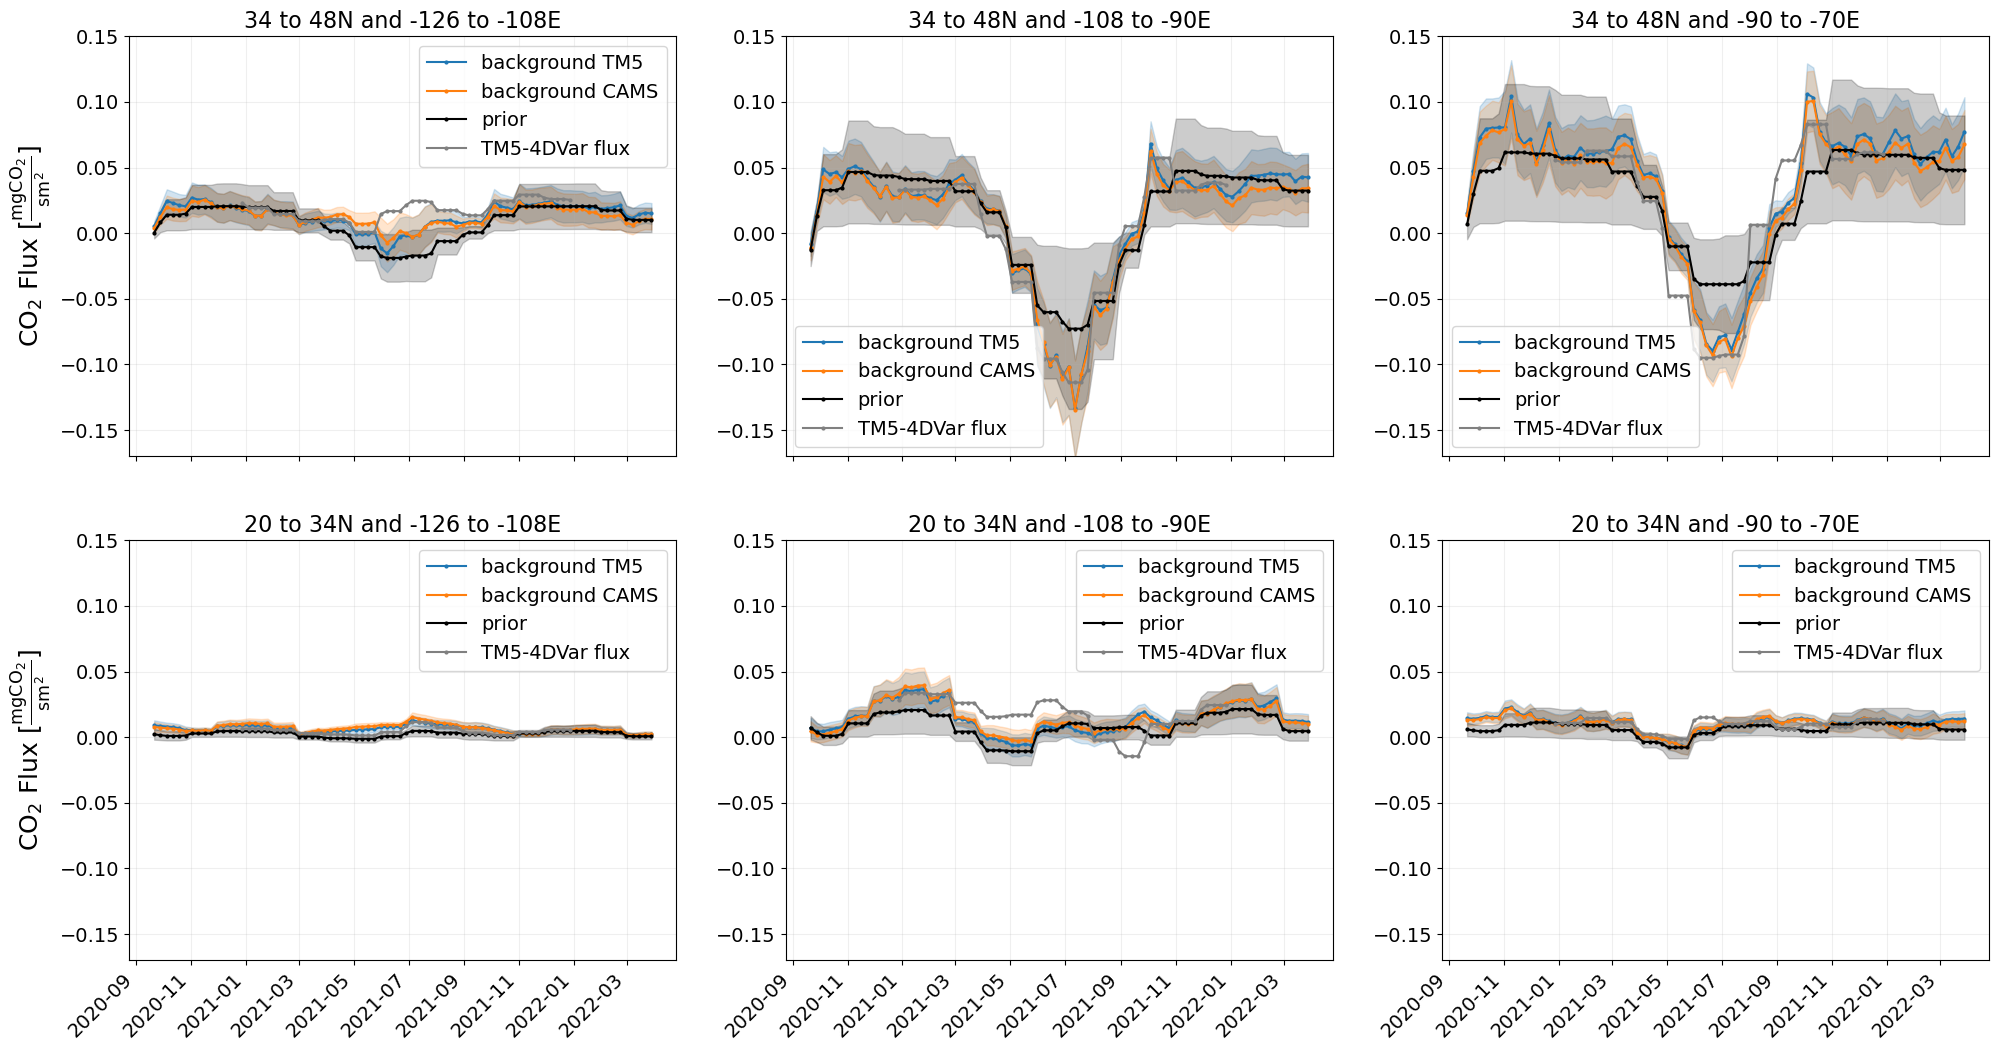

In [12]:
fig,axs=plt.subplots(2,3,figsize=(24,12))
min_max=[-0.17,0.17]
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
label_set=['background TM5','background CAMS' ]                           # ['NEE ampl.','NEE 2*ampl.','NEE 0.5*ampl.','NEE scaled', 'no diurnal']
datasets= [TM5, CAMS ]                                  # [nee_amplitude,nee2_amplitude,nee05_amplitude,scaled, no_diurnal]
for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        k=0
        for k,data in enumerate(datasets):
            temp=data.fluxes
            temp=temp.where(((temp.latitude>= regions_lat[-i-2]) &(temp.latitude<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
            temp=temp.mean(['latitude','longitude'])
            temp['TM5_prior_flux']=temp.TM5_prior_flux*1e6
            temp['prior_uncertainty']=temp.prior_uncertainty*1e6
            temp['TM5_posterior_flux']=temp.TM5_posterior_flux*1e6
            temp['TM5_posterior_std']=temp.TM5_posterior_std*1e6
            axs[i,j].plot(temp.time, temp.TM5_posterior_flux, c=default_colors[k], marker='o', markersize=2, label=f'{label_set[k]}')
            axs[i,j].fill_between(temp.time, temp.TM5_posterior_flux-temp.TM5_posterior_std, temp.TM5_posterior_flux+temp.TM5_posterior_std, color=default_colors[k], alpha=0.2) 
            k+=1

        temp3=TM54DVar_posterior_flux.where(((TM54DVar_posterior_flux.latitude>= regions_lat[-i-2]) &(TM54DVar_posterior_flux.latitude<regions_lat[-i-1])),drop=True)
        temp3=temp3.where(((temp3.longitude>= regions_lon[j]) &(temp3.longitude<regions_lon[j+1])),drop=True)
        temp3=temp3.mean(['latitude','longitude'])
        temp3['total_flux']=temp3.total_flux*1e6

        axs[i,j].plot(temp.time, temp.TM5_prior_flux, c='black', marker='o', markersize=2, label='prior')
        axs[i,j].fill_between(temp.time, temp.TM5_prior_flux-temp.prior_uncertainty, temp.TM5_prior_flux+temp.prior_uncertainty, color='black', alpha=0.2)  
        axs[i,j].plot(temp3.time, temp3.total_flux, c='grey', marker='o', markersize=2, label='TM5-4DVar flux')

        #axs[i,j].tight_layout()
        if j==0:
            axs[i,j].set_ylabel('CO$_2$ Flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=18)        
        axs[i,j].legend(fontsize=14)
        axs[i,j].set_ylim(-0.17,0.15)
        if i==1:
            axs[i,j].tick_params(axis='x', labelrotation=45,labelsize =14)
            axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
        else:
            axs[i,j].tick_params(labelbottom=False)                   
        axs[i,j].tick_params(axis='y', labelsize =14)
        axs[i,j].grid(visible=True, which='major', axis='both', alpha=0.2)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E",fontsize=16)
plt.savefig(f'{savefig}/regional_fluxes_diff_background_model.pdf',bbox_inches='tight')#,transparent=True)
plt.show()
#plt.close()

In [ ]:
prior_path=f'{TM5.path}/{period}_{BG_TM5_ds}_bg.nc'
posterior_path='/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_RemoTeC_2.4.1+IS_cut_weekly.nc'
datasets_dir=[prior_path,posterior_path]
parameters=['TM5_prior_flux','total_flux']
parameters_uncertainty=['prior_uncertainty', False]
labels=['prior','TM5-4DVar']
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
label_set=['background TM5','background CAMS']

colors=['black','grey']
marker=['x','x']
k=0
for k,dataset in enumerate([TM5,CAMS]):
    datasets_dir.append(f'{dataset.path}/{dataset.period}_{dataset.BG_ds}_bg.nc')
    labels.append(label_set[k])
    parameters.append(f'TM5_posterior_flux')
    parameters_uncertainty.append('TM5_posterior_std')
    colors.append(default_colors[k])
    k+=1
    marker.append('o')
print(datasets_dir)
print(parameters)
print(parameters_uncertainty)
print(colors)
print(marker)
plot_inner_2x2_region_fluxes(datasets_dir,labels,parameters,parameters_uncertainty, colors, marker,'different background', analysis_start_date, analysis_end_date,savefig+'/different_background_model_'+'2x2.png')


['inversions_new/TM5_correlations//2x2/with_correlation/footprint_spec001_mr/2ppm_gosat_meas_err/3ppm_insitu_meas_err//20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc', '/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_RemoTeC_2.4.1+IS_cut_weekly.nc', 'inversions_new/TM5_correlations//2x2/with_correlation/footprint_spec001_mr/2ppm_gosat_meas_err/3ppm_insitu_meas_err//20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc', 'inversions_new/CAMS_gosat_inflated//2x2/with_correlation/footprint_spec001_mr/2ppm_gosat_meas_err/3ppm_insitu_meas_err//20201001-20220331_satellite_bg.nc']
['TM5_prior_flux', 'total_flux', 'TM5_posterior_flux', 'TM5_posterior_flux']
['prior_uncertainty', False, 'TM5_posterior_std', 'TM5_posterior_std']
['black', 'grey', '#1f77b4', '#ff7f0e']
['x', 'x', 'o', 'o']
inversions_new/TM5_correlations//2x2/with_correlation/footprint_spec001_mr/2ppm_gosat_meas_err/3ppm_insitu_meas_err//20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc

In [14]:
analy_region_lon

[-126, -70]

### difference in fluxes:

In [15]:
TM5_temp=TM5.fluxes.where(((TM5.fluxes.latitude>= analy_region_lat[0]) &(TM5.fluxes.latitude<analy_region_lat[1])),drop=True)
TM5_temp=TM5_temp.where(((TM5_temp.longitude>= analy_region_lon[0]) &(TM5_temp.longitude<analy_region_lon[1])),drop=True)
CAMS_temp=CAMS.fluxes.where(((CAMS.fluxes.latitude>= analy_region_lat[0]) &(CAMS.fluxes.latitude<analy_region_lat[1])),drop=True)
CAMS_temp=CAMS_temp.where(((CAMS_temp.longitude>= analy_region_lon[0]) &(CAMS_temp.longitude<analy_region_lon[1])),drop=True)
        

In [17]:
print('absolute difference')
print('max: '+str(np.max((TM5_temp.TM5_posterior_flux-CAMS_temp.TM5_posterior_flux).values)*1e6))
print('min: '+ str(np.min((TM5_temp.TM5_posterior_flux-CAMS_temp.TM5_posterior_flux).values)*1e6))
print('mean: '+ str(np.mean((TM5_temp.TM5_posterior_flux-CAMS_temp.TM5_posterior_flux).values)*1e6))
print('std: '+ str(np.std((TM5_temp.TM5_posterior_flux-CAMS_temp.TM5_posterior_flux).values)*1e6))
print('max: '+str(np.max((TM5_temp.TM5_posterior_flux-CAMS_temp.TM5_posterior_flux)/TM5_temp.TM5_posterior_std).values))
print('min: '+ str(np.min((TM5_temp.TM5_posterior_flux-CAMS_temp.TM5_posterior_flux)/TM5_temp.TM5_posterior_std).values))
print('mean: '+ str(np.mean((TM5_temp.TM5_posterior_flux-CAMS_temp.TM5_posterior_flux)/TM5_temp.TM5_posterior_std).values))
print('std: '+ str(np.std((TM5_temp.TM5_posterior_flux-CAMS_temp.TM5_posterior_flux)/TM5_temp.TM5_posterior_std).values))


absolute difference
max: 0.05112518450832682
min: -0.0356404380185323
mean: 0.0012829140344057743
std: 0.004980711963901819
relativ difference:
max: 256.8151478634732
min: -762.8269852639348
mean: -0.014287473485448047
std: 5.718394215073325


In [22]:
TM5.insitu['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']-CAMS.insitu.CAMS_satellite_background


<xarray.DataArray 'TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background' (
                                                                   pointspec: 3004)> Size: 24kB
array([410.41906062, 410.00653912, 411.22687685, ..., 423.39639829,
       423.63547067, 422.87348445], shape=(3004,))
Coordinates:
  * pointspec  (pointspec) int64 24kB 1 2 3 4 8 9 ... 4884 4890 4891 4892 4893
    height     float32 4B 30.0

### difference in background concentration

<>:19: SyntaxWarning: invalid escape sequence '\o'
<>:19: SyntaxWarning: invalid escape sequence '\s'
<>:31: SyntaxWarning: invalid escape sequence '\o'
<>:31: SyntaxWarning: invalid escape sequence '\s'
<>:44: SyntaxWarning: invalid escape sequence '\o'
<>:44: SyntaxWarning: invalid escape sequence '\s'
<>:19: SyntaxWarning: invalid escape sequence '\o'
<>:19: SyntaxWarning: invalid escape sequence '\s'
<>:31: SyntaxWarning: invalid escape sequence '\o'
<>:31: SyntaxWarning: invalid escape sequence '\s'
<>:44: SyntaxWarning: invalid escape sequence '\o'
<>:44: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_3079776/3753440543.py:19: SyntaxWarning: invalid escape sequence '\o'
  print(f'insitu: , $\overline{{d}}={d0}, \sigma={d_std}$' )
/tmp/ipykernel_3079776/3753440543.py:19: SyntaxWarning: invalid escape sequence '\s'
  print(f'insitu: , $\overline{{d}}={d0}, \sigma={d_std}$' )
/tmp/ipykernel_3079776/3753440543.py:31: SyntaxWarning: invalid escape sequence '\o'
  print(f'g

background TM5 - background CAMS
insitu: , $\overline{d}=-0.39, \sigma=0.78$
gosat: , $\overline{d}=0.04, \sigma=0.35$
TCCON: , $\overline{d}=0.24, \sigma=0.37$


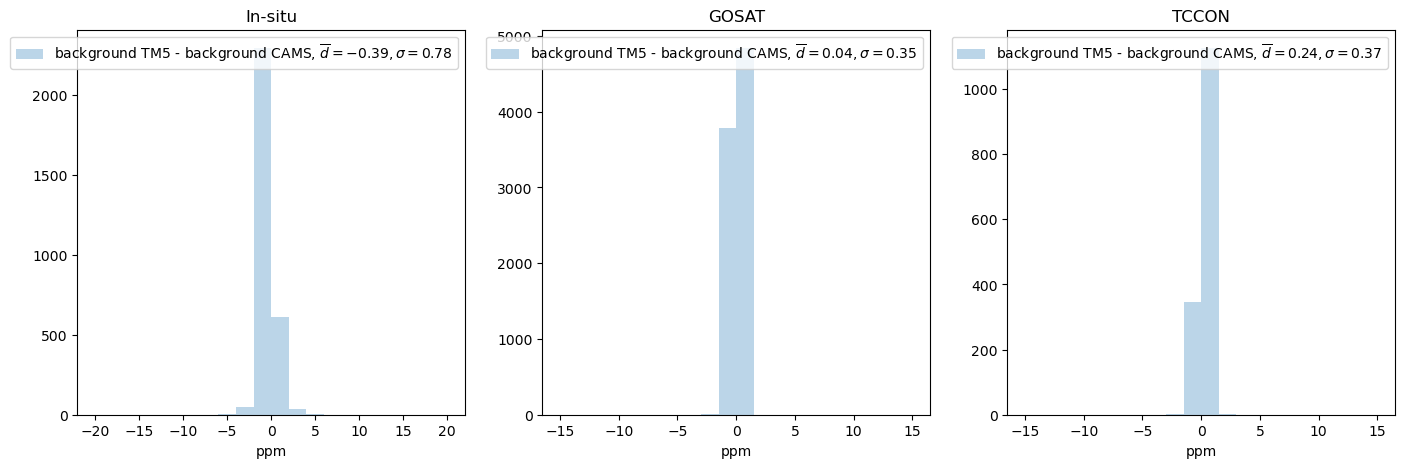

In [28]:
nbins=20
max_min=(-20,20)
fig,axs=plt.subplots(1,3,figsize=(17,5))

title=['In-situ', 'GOSAT','TCCON']
var=['posterior_diff']
label_0=['$K*x_{TM5} +y_{bg} -y_{meas}$','$K*x_{prior} +y_{bg} -y_{meas}$','$K*x_{posterior} +y_{bg} -y_{meas}$']
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
label_set=['background TM5 - background CAMS' ]                           # ['NEE ampl.','NEE 2*ampl.','NEE 0.5*ampl.','NEE scaled', 'no diurnal']
datasets= [TM5, CAMS ]
k=0

print(label_set[k])
temp=TM5.insitu['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']-CAMS.insitu.CAMS_satellite_background
d0=np.round(np.mean(temp).compute().item(),2)
d_abs=np.round(np.mean(np.abs(temp)).compute().item(),2)
d_std=np.round(np.std(temp).compute().item(),2)
label=fr'{label_set[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
print(f'insitu: , $\overline{{d}}={d0}, \sigma={d_std}$' )
axs[0].hist(temp,alpha=0.3,color=default_colors[k], bins=nbins, range=max_min, label=label)
axs[0].legend()
axs[0].set_xlabel('ppm')
axs[0].set_title(title[0])

max_min=(-15,15)
temp=TM5.gosat['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']-CAMS.gosat.CAMS_satellite_background
d0=np.round(np.mean(temp).compute().item(),2)
d_abs=np.round(np.mean(np.abs(temp)).compute().item(),2)
d_std=np.round(np.std(temp).compute().item(),2)
label=fr'{label_set[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
print(f'gosat: , $\overline{{d}}={d0}, \sigma={d_std}$' )
axs[1].hist(temp,alpha=0.3,color=default_colors[k], bins=nbins, range=max_min, label=label)
axs[1].legend()
axs[1].set_xlabel('ppm')
axs[1].set_title(title[1])


max_min=(-15,15)
temp=TM5.tccon['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']-CAMS.tccon.CAMS_satellite_background
d0=np.round(np.mean(temp).compute().item(),2)
d_abs=np.round(np.mean(np.abs(temp)).compute().item(),2)
d_std=np.round(np.std(temp).compute().item(),2)
label=fr'{label_set[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
print(f'TCCON: , $\overline{{d}}={d0}, \sigma={d_std}$' )
axs[2].hist(temp,alpha=0.3,color=default_colors[k], bins=nbins, range=max_min, label=label)
axs[2].legend()
axs[2].set_xlabel('ppm')
axs[2].set_title(title[2])
k+=1

plt.savefig(f'{savefig}/hist_different_background_model.png')

In [34]:
temp_gosat=TM5.gosat['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']-CAMS.gosat.CAMS_satellite_background
temp_insitu=TM5.insitu['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']-CAMS.insitu.CAMS_satellite_background
temp_gosat

<xarray.DataArray (pointspec: 8634)> Size: 69kB
array([-0.20159824, -0.20078361, -0.20217493, ...,  0.43097246,
        0.26116515,  0.20232882], shape=(8634,))
Coordinates:
  * pointspec  (pointspec) int64 69kB 0 1 2 3 4 ... 10730 10731 10732 10733
    height     float32 4B 30.0

In [40]:
temp_gosat=TM5.gosat['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']-CAMS.gosat.CAMS_satellite_background
temp_insitu=TM5.insitu['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']-CAMS.insitu.CAMS_satellite_background
temp=xr.concat([temp_gosat, temp_insitu], dim='pointspec')
d0=np.round(np.mean(temp).compute().item(),2)
d_abs=np.round(np.mean(np.abs(temp)).compute().item(),2)
d_std=np.round(np.std(temp).compute().item(),2)
print(f'insitu+gosat: , $\overline{{d}}={d0}, \sigma={d_std}$' )

insitu+gosat: , $\overline{d}=-0.07, \sigma=0.54$


<>:7: SyntaxWarning: invalid escape sequence '\o'
<>:7: SyntaxWarning: invalid escape sequence '\s'
<>:7: SyntaxWarning: invalid escape sequence '\o'
<>:7: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_3079776/3317955401.py:7: SyntaxWarning: invalid escape sequence '\o'
  print(f'insitu+gosat: , $\overline{{d}}={d0}, \sigma={d_std}$' )
/tmp/ipykernel_3079776/3317955401.py:7: SyntaxWarning: invalid escape sequence '\s'
  print(f'insitu+gosat: , $\overline{{d}}={d0}, \sigma={d_std}$' )


### difference in modeled - measured

<>:21: SyntaxWarning: invalid escape sequence '\o'
<>:21: SyntaxWarning: invalid escape sequence '\s'
<>:33: SyntaxWarning: invalid escape sequence '\o'
<>:33: SyntaxWarning: invalid escape sequence '\s'
<>:46: SyntaxWarning: invalid escape sequence '\o'
<>:46: SyntaxWarning: invalid escape sequence '\s'
<>:21: SyntaxWarning: invalid escape sequence '\o'
<>:21: SyntaxWarning: invalid escape sequence '\s'
<>:33: SyntaxWarning: invalid escape sequence '\o'
<>:33: SyntaxWarning: invalid escape sequence '\s'
<>:46: SyntaxWarning: invalid escape sequence '\o'
<>:46: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_3079776/3244423675.py:21: SyntaxWarning: invalid escape sequence '\o'
  print(f'insitu: , $\overline{{d}}={d0}, \sigma={d_std}$' )
/tmp/ipykernel_3079776/3244423675.py:21: SyntaxWarning: invalid escape sequence '\s'
  print(f'insitu: , $\overline{{d}}={d0}, \sigma={d_std}$' )
/tmp/ipykernel_3079776/3244423675.py:33: SyntaxWarning: invalid escape sequence '\o'
  print(f'g

background TM5
insitu: , $\overline{d}=0.07, \sigma=2.82$
gosat: , $\overline{d}=0.05, \sigma=2.53$
TCCON: , $\overline{d}=-0.7, \sigma=1.9$
background CAMS
insitu: , $\overline{d}=-0.07, \sigma=2.77$
gosat: , $\overline{d}=-0.01, \sigma=2.55$
TCCON: , $\overline{d}=-0.96, \sigma=1.92$


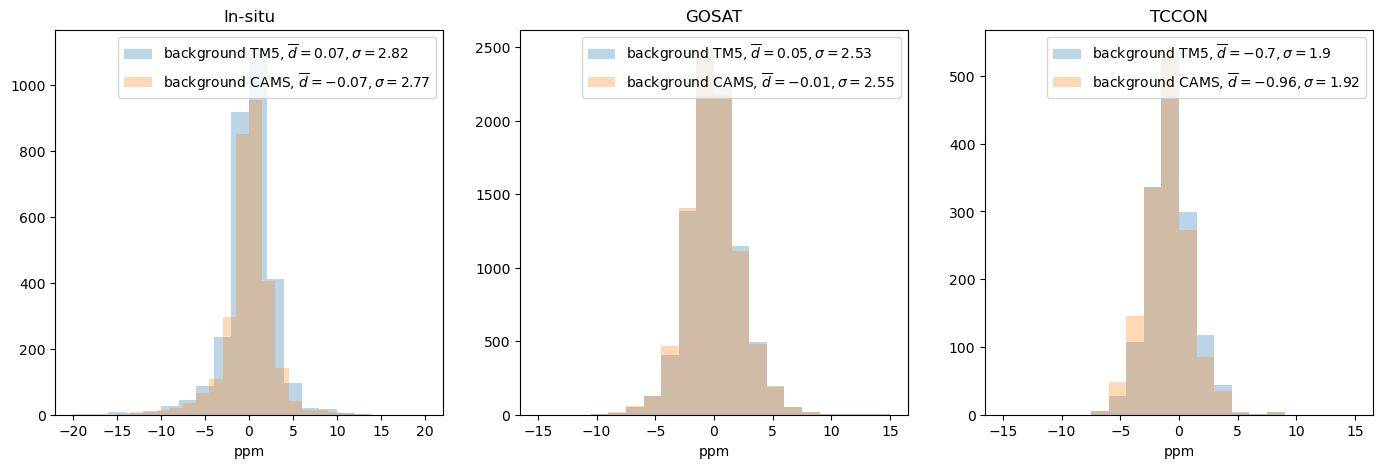

In [29]:
nbins=20
max_min=(-20,20)
fig,axs=plt.subplots(1,3,figsize=(17,5))

title=['In-situ', 'GOSAT','TCCON']
var=['posterior_diff']
label_0=['$K*x_{TM5} +y_{bg} -y_{meas}$','$K*x_{prior} +y_{bg} -y_{meas}$','$K*x_{posterior} +y_{bg} -y_{meas}$']
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
label_set=['background TM5','background CAMS' ]                           # ['NEE ampl.','NEE 2*ampl.','NEE 0.5*ampl.','NEE scaled', 'no diurnal']
datasets= [TM5, CAMS ]
k=0
for k,data in enumerate(datasets):
    if False: #g_err==1 or g_err==2 or g_err==3:
        continue
    print(label_set[k])
    temp=data.insitu
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    label=fr'{label_set[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
    print(f'insitu: , $\overline{{d}}={d0}, \sigma={d_std}$' )
    axs[0].hist(temp.posterior_diff,alpha=0.3,color=default_colors[k], bins=nbins, range=max_min, label=label)
    axs[0].legend()
    axs[0].set_xlabel('ppm')
    axs[0].set_title(title[0])

    max_min=(-15,15)
    temp=data.gosat
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    label=fr'{label_set[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
    print(f'gosat: , $\overline{{d}}={d0}, \sigma={d_std}$' )
    axs[1].hist(temp.posterior_diff,alpha=0.3,color=default_colors[k], bins=nbins, range=max_min, label=label)
    axs[1].legend()
    axs[1].set_xlabel('ppm')
    axs[1].set_title(title[1])

    
    max_min=(-15,15)
    temp=data.tccon
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    label=fr'{label_set[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
    print(f'TCCON: , $\overline{{d}}={d0}, \sigma={d_std}$' )
    axs[2].hist(temp.posterior_diff,alpha=0.3,color=default_colors[k], bins=nbins, range=max_min, label=label)
    axs[2].legend()
    axs[2].set_xlabel('ppm')
    axs[2].set_title(title[2])
    k+=1

plt.savefig(f'{savefig}/hist_different_background_model.png')

### difference in modeled

In [16]:
CAMS.gosat=CAMS.gosat.mean('time')

<>:19: SyntaxWarning: invalid escape sequence '\o'
<>:19: SyntaxWarning: invalid escape sequence '\s'
<>:31: SyntaxWarning: invalid escape sequence '\o'
<>:31: SyntaxWarning: invalid escape sequence '\s'
<>:44: SyntaxWarning: invalid escape sequence '\o'
<>:44: SyntaxWarning: invalid escape sequence '\s'
<>:19: SyntaxWarning: invalid escape sequence '\o'
<>:19: SyntaxWarning: invalid escape sequence '\s'
<>:31: SyntaxWarning: invalid escape sequence '\o'
<>:31: SyntaxWarning: invalid escape sequence '\s'
<>:44: SyntaxWarning: invalid escape sequence '\o'
<>:44: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1817330/3149953806.py:19: SyntaxWarning: invalid escape sequence '\o'
  print(f'insitu: , $\overline{{d}}={d0}, \sigma={d_std}$' )
/tmp/ipykernel_1817330/3149953806.py:19: SyntaxWarning: invalid escape sequence '\s'
  print(f'insitu: , $\overline{{d}}={d0}, \sigma={d_std}$' )
/tmp/ipykernel_1817330/3149953806.py:31: SyntaxWarning: invalid escape sequence '\o'
  print(f'g

background TM5 - background CAMS
insitu: , $\overline{d}=0.53, \sigma=0.47$
gosat: , $\overline{d}=0.02, \sigma=0.11$
TCCON: , $\overline{d}=0.02, \sigma=0.08$


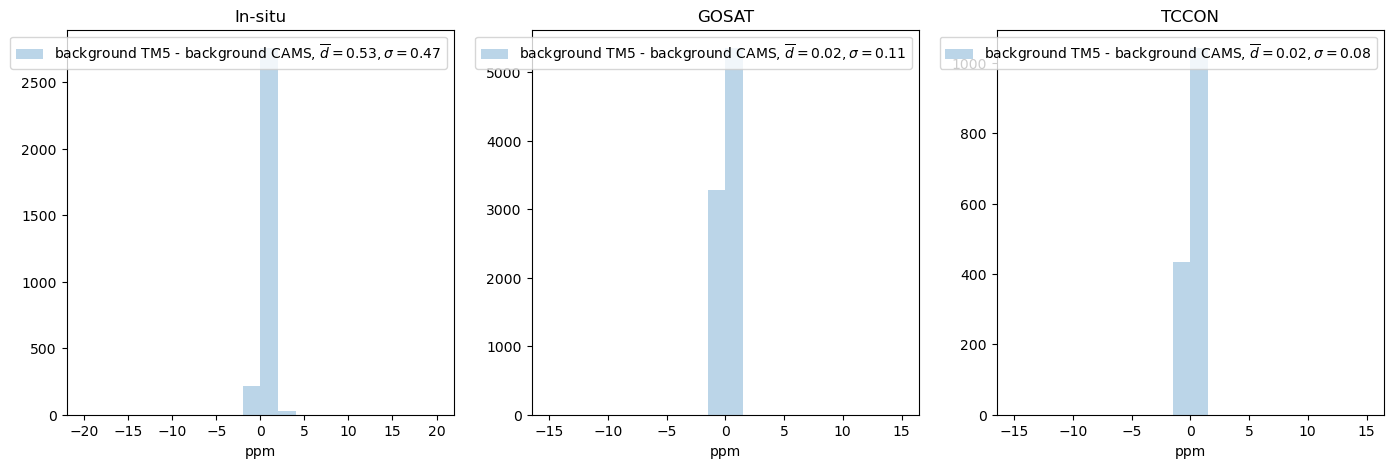

In [17]:
nbins=20
max_min=(-20,20)
fig,axs=plt.subplots(1,3,figsize=(17,5))

title=['In-situ', 'GOSAT','TCCON']
var=['posterior_diff']
label_0=['$K*x_{TM5} +y_{bg} -y_{meas}$','$K*x_{prior} +y_{bg} -y_{meas}$','$K*x_{posterior} +y_{bg} -y_{meas}$']
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
label_set=['background TM5 - background CAMS' ]                           # ['NEE ampl.','NEE 2*ampl.','NEE 0.5*ampl.','NEE scaled', 'no diurnal']
datasets= [TM5, CAMS ]
k=0

print(label_set[k])
temp=TM5.insitu.posterior_val-CAMS.insitu.posterior_val
d0=np.round(np.mean(temp).compute().item(),2)
d_abs=np.round(np.mean(np.abs(temp)).compute().item(),2)
d_std=np.round(np.std(temp).compute().item(),2)
label=fr'{label_set[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
print(f'insitu: , $\overline{{d}}={d0}, \sigma={d_std}$' )
axs[0].hist(temp,alpha=0.3,color=default_colors[k], bins=nbins, range=max_min, label=label)
axs[0].legend()
axs[0].set_xlabel('ppm')
axs[0].set_title(title[0])

max_min=(-15,15)
temp=TM5.gosat.posterior_val-CAMS.gosat.posterior_val
d0=np.round(np.mean(temp).compute().item(),2)
d_abs=np.round(np.mean(np.abs(temp)).compute().item(),2)
d_std=np.round(np.std(temp).compute().item(),2)
label=fr'{label_set[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
print(f'gosat: , $\overline{{d}}={d0}, \sigma={d_std}$' )
axs[1].hist(temp,alpha=0.3,color=default_colors[k], bins=nbins, range=max_min, label=label)
axs[1].legend()
axs[1].set_xlabel('ppm')
axs[1].set_title(title[1])


max_min=(-15,15)
temp=TM5.tccon.posterior_val-CAMS.tccon.posterior_val
d0=np.round(np.mean(temp).compute().item(),2)
d_abs=np.round(np.mean(np.abs(temp)).compute().item(),2)
d_std=np.round(np.std(temp).compute().item(),2)
label=fr'{label_set[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
print(f'TCCON: , $\overline{{d}}={d0}, \sigma={d_std}$' )
axs[2].hist(temp,alpha=0.3,color=default_colors[k], bins=nbins, range=max_min, label=label)
axs[2].legend()
axs[2].set_xlabel('ppm')
axs[2].set_title(title[2])
k+=1

plt.savefig(f'{savefig}/hist_different_background_model_different_modeled_values.png')

# outside buffer zone

In [11]:
TM5_temp=TM5.fluxes.where((TM5.fluxes.latitude< analy_region_lat[0]) |(TM5.fluxes.latitude>analy_region_lat[1])|(TM5.fluxes.longitude< analy_region_lon[0]) |(TM5.fluxes.longitude>analy_region_lon[1]),drop=True)
        

In [12]:
CAMS_temp=CAMS.fluxes.where((CAMS.fluxes.latitude< analy_region_lat[0]) |(CAMS.fluxes.latitude>analy_region_lat[1])|(CAMS.fluxes.longitude< analy_region_lon[0]) |(CAMS.fluxes.longitude>analy_region_lon[1]),drop=True)


In [13]:
print('absolute difference')
print('max: '+str(np.max((TM5_temp.TM5_posterior_flux-CAMS_temp.TM5_posterior_flux)).values*1e6))
print('min: '+ str(np.min((TM5_temp.TM5_posterior_flux-CAMS_temp.TM5_posterior_flux)).values*1e6))
print('mean: '+ str(np.mean((TM5_temp.TM5_posterior_flux-CAMS_temp.TM5_posterior_flux)).values*1e6))
print('std: '+ str(np.std((TM5_temp.TM5_posterior_flux-CAMS_temp.TM5_posterior_flux)).values*1e6))
print('relativ difference:')
print('max: '+str(np.max((TM5_temp.TM5_posterior_flux-CAMS_temp.TM5_posterior_flux)/TM5_temp.TM5_posterior_flux).values))
print('min: '+ str(np.min((TM5_temp.TM5_posterior_flux-CAMS_temp.TM5_posterior_flux)/TM5_temp.TM5_posterior_flux).values))
print('mean: '+ str(np.mean((TM5_temp.TM5_posterior_flux-CAMS_temp.TM5_posterior_flux)/TM5_temp.TM5_posterior_flux).values))
print('std: '+ str(np.std((TM5_temp.TM5_posterior_flux-CAMS_temp.TM5_posterior_flux)/TM5_temp.TM5_posterior_flux).values))


absolute difference
max: 0.07284101611991084
min: -0.058733010264858554
mean: 0.0030542311710251
std: 0.007270896355216282
relativ difference:
max: 2589.4541695736757
min: -673.7226058140798
mean: 0.1759308406525467
std: 17.78208852217166


In [30]:
def plot_map(data,label,ax,vmin=-0.6,vmax=0.6):
    plot=data.plot(ax=ax, cmap='RdBu_r', vmin=vmin, vmax=vmax, cbar_kwargs={'location':'right','shrink':0.85, 'label':label})
    plot.colorbar.ax.xaxis.label.set_size(12)
    plot.colorbar.ax.tick_params(labelsize=12)
        
    ax.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='g')
    ax.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='g')
    ax.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='g')
    ax.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='g')
    
    ax.set_xlabel('longitude')
    ax.set_ylabel('latitude')
    # Add coastlines
    ax.coastlines(linewidth=0.5, alpha=0.3)
    # Add U.S. state borders
    ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
    gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 10}
    gl.ylabel_style = {'size': 10}
    ax.grid(c='lightgrey')
    ax.set_xlim(-134,-62) 
    ax.set_ylim(12,56)
    ax.tick_params(labelsize=20)
    ax.set_title('')
    ax.set_aspect(1)

<>:7: SyntaxWarning: invalid escape sequence '\m'
<>:7: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_3700482/3817584583.py:7: SyntaxWarning: invalid escape sequence '\m'
  plot.colorbar.set_label('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]', size=18)


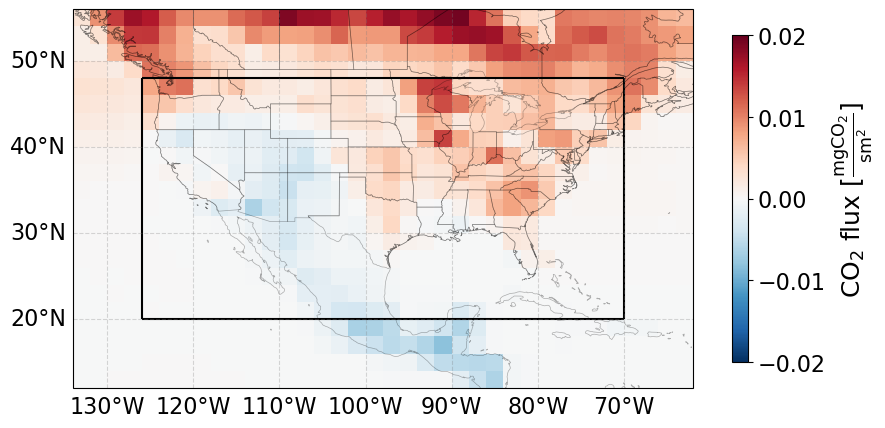

In [19]:
fig,ax=plt.subplots(figsize=(10,5), subplot_kw={'projection': ccrs.PlateCarree()})
#fig.suptitle('',fontsize=14)
vmin=0.02
data=(TM5.fluxes.TM5_posterior_flux-CAMS.fluxes.TM5_posterior_flux).mean('time')*1e6
plot=data.plot(ax=ax, cmap='RdBu_r', vmin=-vmin, vmax=vmin,rasterized=True, cbar_kwargs={'location':'right','shrink':0.85})
plot.colorbar.ax.tick_params(labelsize=16)
plot.colorbar.set_label('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]', size=18)


ax.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='black')
ax.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='black')
ax.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='black')
ax.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='black')

ax.set_xlabel('longitude')
ax.set_ylabel('latitude')
# Add coastlines
ax.coastlines(linewidth=0.5, alpha=0.3)
# Add U.S. state borders
ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 16}
gl.ylabel_style = {'size': 16}
ax.grid(c='lightgrey')
ax.set_xlim(-134,-62) 
ax.set_ylim(12,56)
ax.tick_params(labelsize=20)
ax.set_title('')
ax.set_aspect(1)
plt.savefig(f'{savefig}/map_difference_background_model.pdf')
plt.show()
